# Paso 9 · Loop shaping, prefiltro y verificación (con Python)

Notebook del **Paso 9**: construir el compensador $G$ para que $L_0=GP_0$ respete los bounds, diseñar el prefiltro $F$ y **verificar** con toda la familia.

| Concepto matemático | Concepto de programación |
|---|---|
| $L_0=G\,P_0$ y el efecto de cada bloque | composición de funciones, tabla de etapas |
| $L_0$ debe caer en la zona permitida de cada $\omega$ | máscaras booleanas de `spec_ok`, bucle sobre $\omega$ |
| prefiltro $F$: dos grados de libertad | bandas $[T_L,T_U]$ frente a $|T_i|F$ |
| verificación densa | barrido de 2000 frecuencias × 221 plantas |
| respuesta al escalón | `scipy.signal.step` con polinomios |

In [1]:
import numpy as np
import matplotlib.pyplot as plt

AZUL, NARANJA, TINTA, GRIS = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e3e2de", "axes.axisbelow": True,
                     "font.size": 10})
np.set_printoptions(precision=4, suppress=True)

In [2]:
from scipy import signal
from nbhelp import db, wrapfase, carta_nichols, AZUL, NARANJA, TINTA, GRIS, VERDE
from qft import KS, AS, P, P0, family, ratio, spec_ok, TU, TL, WD, WS, delta_db
PH = np.arange(-260, -59, 1.0); GG = np.arange(-50, 50.5, 0.5)
WL = [0.3, 0.5, 1, 2, 3, 5, 8, 12, 20, 40]          # frecuencias de diseño

def permitido(w):
    X, Y = np.meshgrid(PH, GG); a, b, c = spec_ok(w, 10**(Y/20)*np.exp(1j*np.radians(X)), ratio(w)); return a & b & c
MAPAS = {w: permitido(w) for w in WL}
print("mapas listos para", len(WL), "frecuencias")

mapas listos para 10 frecuencias


## 1. Qué se busca

Con $G$ buscamos que, para cada $\omega\in$ WL, el punto $L_0(j\omega)=G(j\omega)P_0(j\omega)$ esté en la zona **permitida** del mapa, y que la curva completa no «salte» entre medias. Recordemos el efecto de los bloques:

- ganancia $K$ ⇒ sube/baja $L_0$; - cero $(1+s/z)$ ⇒ sube magnitud y **adelanta fase**; - polo $(1+s/p)$ ⇒ al revés. Lo más barato en fase es un **adelanto** (cero seguido de un polo más rápido).

## 2. Las cuatro etapas

Probamos cuatro compensadores, cada uno añade un bloque:

In [3]:
etapas = [("(a) G = 1",                        lambda w: 1 + 0j*w),
          ("(b) G = 5 (solo ganancia)",         lambda w: 5 + 0j*w),
          ("(c) G = 5(1 + s/2) (añadir cero)",  lambda w: 5*(1 + 1j*w/2)),
          ("(d) G = 5(1 + s/2)/(1 + s/20) (añadir polo)", lambda w: 5*(1 + 1j*w/2)/(1 + 1j*w/20))]

def incumple(Gf):
    mal = []
    for w in WL:
        l0 = np.array(Gf(w) * P0(w)); a, b, c = spec_ok(w, l0, ratio(w))
        if not (a and b and c): mal.append(w)
    return mal

for nombre, Gf in etapas:
    print(f"{nombre:<48} incumple en ω = {incumple(Gf)}")

(a) G = 1                                        incumple en ω = [0.3, 0.5, 1, 2]
(b) G = 5 (solo ganancia)                        incumple en ω = [0.5, 1, 2, 3, 5]
(c) G = 5(1 + s/2) (añadir cero)                 incumple en ω = []
(d) G = 5(1 + s/2)/(1 + s/20) (añadir polo)      incumple en ω = []


(a) y (b) fallan: la ganancia sola no basta, porque la fase queda demasiado cerca de $-180^\circ$. (c) cumple en todo, pero $|G|$ crece sin límite (no realizable, amplifica ruido). (d) añade un polo en 20 que acota $|G(\infty)|=50$ (34 dB) y **sigue cumpliendo**: es el diseño final, $G=\frac{50(s+2)}{s+20}$.

## 3. El diseño final sobre el Nichols

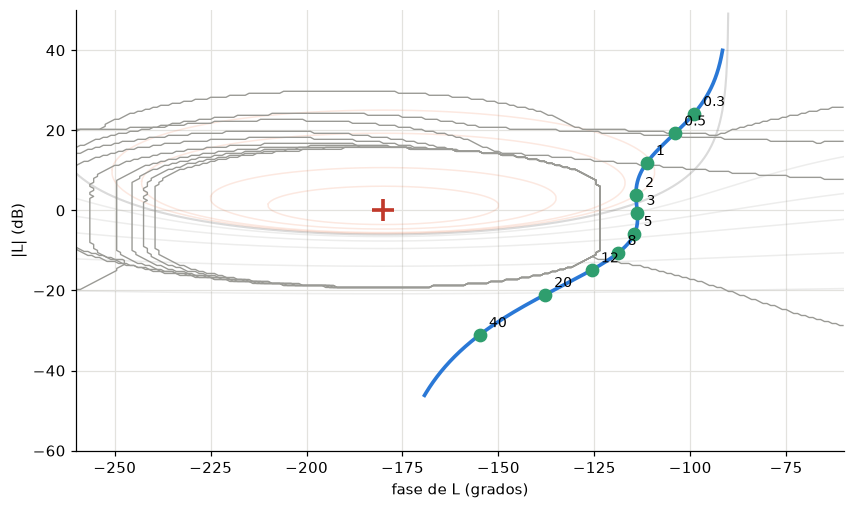

    ω   fase L0   |L0| dB
  0.3    -99.0°     24.16
  0.5   -104.0°     19.29
    1   -111.3°     11.93
    2   -114.1°      3.94
    3   -113.8°     -0.54
    5   -114.5°     -5.81
    8   -118.7°    -10.55
   12   -125.7°    -14.87
   20   -137.8°    -21.04
   40   -154.9°    -31.06


In [4]:
G = etapas[3][1]
wc = np.logspace(-1.3, 2, 500)
fig, ax = plt.subplots(figsize=(9, 5.2)); carta_nichols(ax, (-260, -60), (-60, 50), alpha=0.15)
for w, m in MAPAS.items(): ax.contour(PH, GG, m.astype(float), levels=[0.5], colors=["#9a9a95"], linewidths=0.9)
z = G(wc) * P0(wc); ax.plot(wrapfase(z), db(z), color=AZUL, lw=2.4)
for w in WL:
    l0 = G(w)*P0(w); ax.plot(float(wrapfase(l0)), db(l0), "o", color=VERDE, ms=8)
    ax.annotate(f"{w:g}", (float(wrapfase(l0)), db(l0)), xytext=(6, 5), textcoords="offset points", fontsize=9)
plt.show()
print(f"{'ω':>5} {'fase L0':>9} {'|L0| dB':>9}")
for w in WL: l0 = G(w)*P0(w); print(f"{w:>5g} {float(wrapfase(l0)):>8.1f}° {db(l0):>9.2f}")

## 4. El compensador: su Bode

$G(s)=5\,\dfrac{1+s/2}{1+s/20}$: 14 dB hasta el cero ($\omega=2$), sube +20 dB/dec hasta el polo ($\omega=20$) y queda plano en $G(\infty)=50$ (34 dB). Aporta fase de hasta $\approx55^\circ$ cerca de $\omega=6$.

G(0) = 14.0 dB ;  G(∞) = 34.0 dB ;  fase máxima 54.9° en ω = 6.4


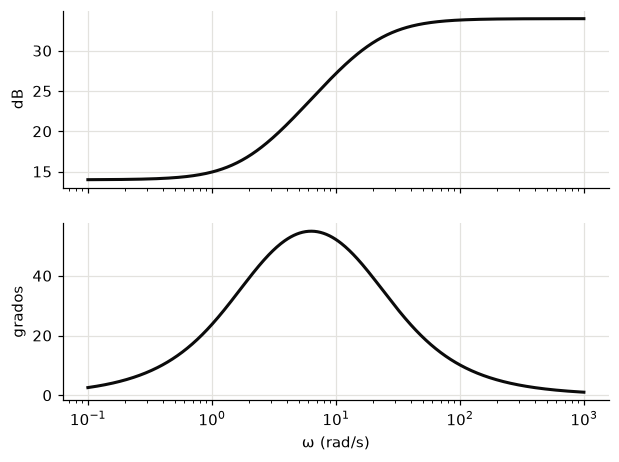

In [5]:
w = np.logspace(-1, 3, 500); g = G(w)
print(f"G(0) = {db(g[0]):.1f} dB ;  G(∞) = {db(G(1e5)):.1f} dB ;  fase máxima {np.degrees(np.angle(g)).max():.1f}° en ω = {w[np.argmax(np.angle(g))]:.1f}")
fig, (m, p) = plt.subplots(2, 1, figsize=(6.4, 4.6), sharex=True)
m.semilogx(w, db(g), color=TINTA, lw=2); p.semilogx(w, np.degrees(np.angle(g)), color=TINTA, lw=2)
m.set_ylabel("dB"); p.set_ylabel("grados"); p.set_xlabel("ω (rad/s)"); plt.show()

## 5. El prefiltro $F$: dos grados de libertad

$G$ se diseñó para estabilidad y rechazo; el **seguimiento** se ajusta con $F$ (que no está dentro del lazo). Sin $F$, las $|T_i|$ no caben en la banda $[T_L,T_U]$; con $F=\dfrac{1}{1+s/1.2}$ sí:

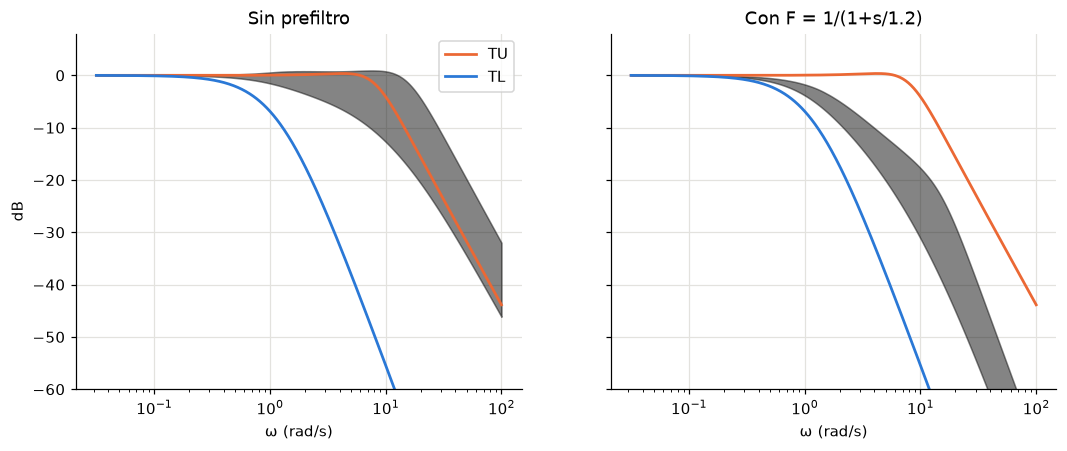

¿cabe en la banda sin prefiltro? False | ¿con prefiltro? True


In [6]:
wf = np.logspace(-1.5, 2, 600)
Tmax = []; Tmin = []
for x in wf:
    L = G(x) * family(x); T = np.abs(L/(1+L)); Tmax.append(T.max()); Tmin.append(T.min())
Tmax = np.array(Tmax); Tmin = np.array(Tmin)
F = lambda w: 1 / (1 + 1j*w/1.2)

fig, (a, b) = plt.subplots(1, 2, figsize=(11.5, 4.2), sharey=True)
for ax, fac, t in ((a, 1, "Sin prefiltro"), (b, np.abs(F(wf)), "Con F = 1/(1+s/1.2)")):
    ax.semilogx(wf, db(TU(wf)), color=NARANJA, lw=1.8, label="TU"); ax.semilogx(wf, db(TL(wf)), color=AZUL, lw=1.8, label="TL")
    ax.fill_between(wf, 20*np.log10(Tmin*fac), 20*np.log10(Tmax*fac), color=TINTA, alpha=0.5)
    ax.set_ylim(-60, 8); ax.set_xlabel("ω (rad/s)"); ax.set_title(t)
a.set_ylabel("dB"); a.legend(); plt.show()

dentro = lambda fac: bool(((20*np.log10(Tmin*fac) >= db(TL(wf)) - 1e-6) & (20*np.log10(Tmax*fac) <= db(TU(wf)) + 1e-6)).all())
print("¿cabe en la banda sin prefiltro?", dentro(1), "| ¿con prefiltro?", dentro(np.abs(F(wf))))

## 6. Verificación 1: respuesta en frecuencia (toda la familia)

El diseño usó 10 frecuencias; la **verificación** comprueba 2000 (y las 221 plantas):

In [7]:
wd = np.logspace(-2, 3, 2000)
mx = 0; S5 = 0; S1 = 0
for x in wd:
    L = G(x) * family(x); T = np.abs(L/(1+L)); S = 1/np.abs(1+L); mx = max(mx, T.max())
    if x <= 0.5: S5 = max(S5, S.max())
    elif x <= 1.0: S1 = max(S1, S.max())
print(f"max |T|            = {db(mx):.2f} dB   (límite 1.58 dB)")
print(f"max |S|  ω ≤ 0.5   = {S5:.3f}        (límite 0.3)")
print(f"max |S|  0.5<ω≤1   = {S1:.3f}        (límite 0.5)")

pm = []; gm = []
wm = np.logspace(-2, 3, 6000)
for K in KS:
    for a in AS:
        L = G(wm)*P(wm, K, a); i = np.argmin(abs(abs(L)-1)); pm.append(180 + np.degrees(np.angle(L[i])))
        ph = np.unwrap(np.angle(L)); j = np.where(ph < -np.pi)[0]
        if len(j): gm.append(-db(L[j[0]]))
print(f"margen de fase de toda la familia: {min(pm):.1f}° a {max(pm):.1f}°")
print(f"margen de ganancia mínimo        : {min(gm):.1f} dB" if gm else "sin cruce de -180° (margen de ganancia infinito)")

max |T|            = 0.94 dB   (límite 1.58 dB)
max |S|  ω ≤ 0.5   = 0.279        (límite 0.3)
max |S|  0.5<ω≤1   = 0.473        (límite 0.5)
margen de fase de toda la familia: 56.0° a 95.7°
sin cruce de -180° (margen de ganancia infinito)


## 7. Verificación 2: respuestas en el tiempo

Escalón unitario para 56 plantas de la familia, con el diseño completo $F\,G$. Entre los modelos $T_U$ (rápido) y $T_L$ (lento) debe quedar la nube.

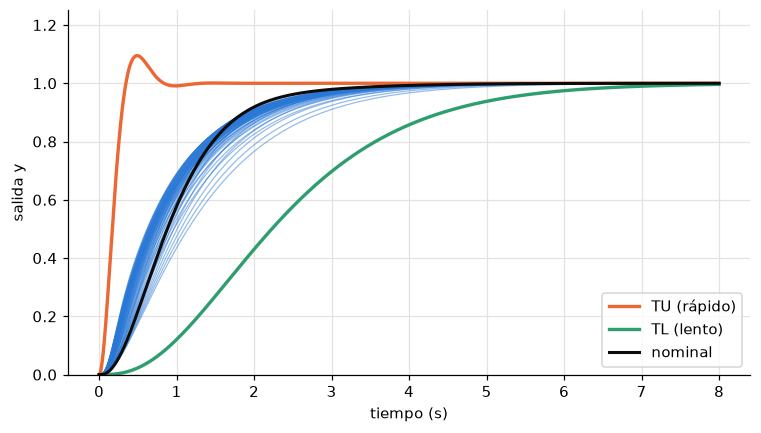

valor máximo alcanzado por la familia = 1.000 (sin sobreimpulso si es < 1)


In [8]:
t = np.linspace(0, 8, 1200)
def cl_tf(K, a):
    # y/r = F·G·P/(1+G·P) con G = 5(1+s/2)/(1+s/20) = 50(s+2)/(s+20)  y  P = K/(s(s+a)),  F = 1.2/(s+1.2)
    nG, dG = [50, 100], [1, 20]                           # numerador y denominador de G
    nL = np.polymul(nG, [K]); dL = np.polymul(dG, [1, a, 0])
    cl = np.polyadd(dL, nL)                                # 1 + L
    num = np.polymul(nL, [1.2]); den = np.polymul(cl, [1, 1.2])
    return num, den

fig, ax = plt.subplots(figsize=(8, 4.3)); sobre = []
for K in KS[::2]:
    for a in AS[::2]:
        tt, y = signal.step(cl_tf(K, a), T=t); ax.plot(tt, y, color=AZUL, lw=0.8, alpha=0.5); sobre.append(y.max())
tt, yU = signal.step(([64], [1, 9.6, 64]), T=t); tt, yL = signal.step(([1.728], np.poly([-1.2]*3)), T=t)
ax.plot(tt, yU, color=NARANJA, lw=2.2, label="TU (rápido)"); ax.plot(tt, yL, color=VERDE, lw=2.2, label="TL (lento)")
tt, y = signal.step(cl_tf(1, 1), T=t); ax.plot(tt, y, color=TINTA, lw=2, label="nominal")
ax.set_xlabel("tiempo (s)"); ax.set_ylabel("salida y"); ax.set_ylim(0, 1.25); ax.legend(); plt.show()
print(f"valor máximo alcanzado por la familia = {max(sobre):.3f} (sin sobreimpulso si es < 1)")

## 8. Qué garantiza y qué no la verificación

Garantiza el comportamiento **de las plantas comprobadas** en las frecuencias comprobadas. No cubre plantas fuera de la caja de parámetros, dinámica no modelada ni no linealidades (Pasos 12 y 15).

## 9. Ejercicio del Paso 9

En $\omega=5$: $P_0(j5)=0.0392\angle-168.7^\circ$ ($-28.1$ dB). Con los bounds de la tabla (fase → ganancia **prohibida**: $-170^\circ$: $-19$ a $15.25$ dB; $-150^\circ$: $-17.5$ a $14$; $-130^\circ$: $-13.5$ a $10$; $-115^\circ$: ninguna):

1. $G(j5)$ para $G=\dfrac{50(s+2)}{s+20}$. 2. $L_0(j5)=GP_0$ en (fase, dB); también el de $G=5$. 3. ¿Cumplen $G=5$ y el compensador final?

**Tu turno.**

In [9]:
# 1) G(j5) = 50 (j5 + 2) / (j5 + 20): módulo en dB y fase
# 2) L0 = G * P0(5) para G = 5 y para el compensador final
# 3) comprobar con spec_ok(5.0, L0, ratio(5.0))
# escribe aquí tu código

In [10]:
p0 = P0(5.0); print(f"P0(j5) = {abs(p0):.4f}∠{np.degrees(np.angle(p0)):.1f}°  ({db(p0):.1f} dB)")
g5 = 50*(5j + 2)/(5j + 20)
print(f"1) G(j5) = {abs(g5):.2f}∠{np.degrees(np.angle(g5)):.1f}°  ->  {db(g5):.2f} dB")
for nombre, Gv in (("G = 5", 5+0j), ("G final", g5)):
    l0 = Gv*p0; a, b, c = spec_ok(5.0, np.array(l0), ratio(5.0))
    print(f"2) {nombre:<8}: L0 = ({float(wrapfase(l0)):.1f}°, {db(l0):.2f} dB)  ->  estab {a}, segui {b}, pert {c}")
print("3) G = 5 cae en (-168.7°, -14.1 dB): dentro del intervalo prohibido (-19 a 15.25 dB a -170°) -> NO cumple.")
print("   El compensador final cae en (-114.5°, -5.8 dB): cerca de -115° no hay ganancia prohibida -> SÍ cumple (el cero aportó fase).")

P0(j5) = 0.0392∠-168.7°  (-28.1 dB)
1) G(j5) = 13.06∠54.2°  ->  22.32 dB
2) G = 5   : L0 = (-168.7°, -14.15 dB)  ->  estab False, segui True, pert True
2) G final : L0 = (-114.5°, -5.81 dB)  ->  estab True, segui True, pert True
3) G = 5 cae en (-168.7°, -14.1 dB): dentro del intervalo prohibido (-19 a 15.25 dB a -170°) -> NO cumple.
   El compensador final cae en (-114.5°, -5.8 dB): cerca de -115° no hay ganancia prohibida -> SÍ cumple (el cero aportó fase).


## 10. Resumen

- Loop shaping = elegir $G$ (ganancia, ceros, polos) para que $L_0=GP_0$ caiga en la zona permitida en cada $\omega$.
- El adelanto (cero + polo) da la fase que falta con la menor ganancia de alta frecuencia.
- El prefiltro $F$ ajusta el seguimiento *fuera* del lazo; $G$ no se toca.
- **Verificación densa** con toda la familia: $\max|T|$, $\max|S|$, márgenes y escalones.

**Siguiente:** Paso 10, QFT en control digital (el ZOH y el periodo de muestreo).